In [1]:
#Cargamos librerias
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
from statsmodels.formula.api import ols
from scipy import stats
from statsmodels.graphics.factorplots import interaction_plot

# ETAPA 1: EXTRACCIÓN DE DATOS

## Base 8: PRINCIPALES CANALES

In [2]:
#Cargar archivo csv
CANALES8 = pd.read_csv('Analisis GAC Full7agosto 2026(Principales Canales).csv', header=None)
CANALES8.shape

(68, 60)

In [3]:
# Revisar la primera columna para identificar los bloques de información
CANALES8.iloc[:, 0].dropna()

0     Principales Canales
4           Ventas X Mes 
5                    Piso
6                   Piso 
7                  Leads 
8              Efectivos 
9                    SDC 
10                   PDM 
11     Citas Programadas 
12       Citas Efectivas 
13                Ventas 
14            Conversion 
15                Aporte 
18                 Plazas
19                Plazas 
20                 Leads 
21             Efectivos 
22                   SDC 
23                   PDM 
24     Citas Programadas 
26       Citas Efectivas 
28                Ventas 
29            Conversion 
30                Aporte 
33               Digital 
34               Digital 
35                 Leads 
36             Efectivos 
37                   SDC 
38                   PDM 
39      Citas Programadas
40       Citas Efectivas 
41                Ventas 
42            Conversion 
43                Aporte 
46               Digital 
47                 Canal 
48                 Leads 
49          

In [4]:
# Extraer el bloque correspondiente al canal Piso
piso = CANALES8.iloc[6:16, 0:31].copy()

# Transponer la información para que cada mes sea una observación
piso = piso.T

# Usar la primera fila como nombres de las columnas
piso.columns = piso.iloc[0]
piso = piso.iloc[1:].reset_index(drop=True)
piso

,Piso,Leads,Efectivos,SDC,PDM,Citas Programadas,Citas Efectivas,Ventas,Conversion,Aporte
0,"Febrero, 24",329,NaN,-,22,9,4,9,2.74%,75.00%
1,"Marzo, 24",19,NaN,-,13,28,16,4,21.05%,57.14%
2,"Abril, 24",76,NaN,-,35,15,6,10,13.16%,125.00%
3,"Mayo, 24",87,NaN,-,40,38,16,1,1.15%,7.69%
4,"Junio, 24",55,NaN,-,28,78,60,3,5.45%,50.00%
5,"Julio, 24",92,NaN,51,35,75,57,10,10.87%,47.62%
6,"Agosto, 24",77,NaN,32,31,65,46,9,11.69%,52.94%
7,"Septiembre, 24",57,NaN,28,28,37,19,6,10.53%,35.29%
8,"Octubre, 24",43,NaN,38,14,31,25,3,6.98%,13.04%
9,"Noviembre, 24",50,NaN,32,25,18,14,11,22.00%,50.00%


In [5]:
# Eliminar espacios en los nombres de las columnas y renombrar la columna de fechas
piso.columns = piso.columns.str.strip()
piso = piso.rename(columns={'Piso': 'Mes'})

# Agregar la variable Canal
piso['Canal'] = 'Piso'
piso

,Mes,Leads,Efectivos,SDC,PDM,Citas Programadas,Citas Efectivas,Ventas,Conversion,Aporte,Canal
0,"Febrero, 24",329,NaN,-,22,9,4,9,2.74%,75.00%,Piso
1,"Marzo, 24",19,NaN,-,13,28,16,4,21.05%,57.14%,Piso
2,"Abril, 24",76,NaN,-,35,15,6,10,13.16%,125.00%,Piso
3,"Mayo, 24",87,NaN,-,40,38,16,1,1.15%,7.69%,Piso
4,"Junio, 24",55,NaN,-,28,78,60,3,5.45%,50.00%,Piso
5,"Julio, 24",92,NaN,51,35,75,57,10,10.87%,47.62%,Piso
6,"Agosto, 24",77,NaN,32,31,65,46,9,11.69%,52.94%,Piso
7,"Septiembre, 24",57,NaN,28,28,37,19,6,10.53%,35.29%,Piso
8,"Octubre, 24",43,NaN,38,14,31,25,3,6.98%,13.04%,Piso
9,"Noviembre, 24",50,NaN,32,25,18,14,11,22.00%,50.00%,Piso


In [6]:
# Extraer el bloque correspondiente al canal Plazas
plazas = CANALES8.iloc[19:31, 0:31].copy()

# Eliminar filas adicionales que no forman parte de las variables principales
plazas = plazas.drop(index=[25, 27])

# Transponer la información para que cada mes sea una observación
plazas = plazas.T

# Usar la primera fila como nombres de las columnas
plazas.columns = plazas.iloc[0]
plazas = plazas.iloc[1:].reset_index(drop=True)
plazas

,Plazas,Leads,Efectivos,SDC,PDM,Citas Programadas,Citas Efectivas,Ventas,Conversion,Aporte
0,"Febrero, 24",0,NaN,-,-,NaN,NaN,0,0.00%,0.00%
1,"Marzo, 24",0,NaN,-,-,NaN,NaN,0,0.00%,0.00%
2,"Abril, 24",25,NaN,-,1,1,NaN,0,0.00%,0.00%
3,"Mayo, 24",28,NaN,-,11,3,2,0,0.00%,0.00%
4,"Junio, 24",68,NaN,-,5,2,2,0,0.00%,0.00%
5,"Julio, 24",294,NaN,-,6,30,8,2,0.68%,9.52%
6,"Agosto, 24",248,NaN,-,17,50,18,3,1.21%,17.65%
7,"Septiembre, 24",52,NaN,-,8,13,4,0,0.00%,0.00%
8,"Octubre, 24",59,NaN,-,5,13,6,2,3.39%,8.70%
9,"Noviembre, 24",154,NaN,-,19,20,10,3,1.95%,13.64%


In [7]:
# Eliminar espacios en los nombres de las columnas y renombrar la columna de fechas
plazas.columns = plazas.columns.str.strip()
plazas = plazas.rename(columns={'Plazas': 'Mes'})

# Agregar la variable Canal
plazas['Canal'] = 'Plazas'
plazas

,Mes,Leads,Efectivos,SDC,PDM,Citas Programadas,Citas Efectivas,Ventas,Conversion,Aporte,Canal
0,"Febrero, 24",0,NaN,-,-,NaN,NaN,0,0.00%,0.00%,Plazas
1,"Marzo, 24",0,NaN,-,-,NaN,NaN,0,0.00%,0.00%,Plazas
2,"Abril, 24",25,NaN,-,1,1,NaN,0,0.00%,0.00%,Plazas
3,"Mayo, 24",28,NaN,-,11,3,2,0,0.00%,0.00%,Plazas
4,"Junio, 24",68,NaN,-,5,2,2,0,0.00%,0.00%,Plazas
5,"Julio, 24",294,NaN,-,6,30,8,2,0.68%,9.52%,Plazas
6,"Agosto, 24",248,NaN,-,17,50,18,3,1.21%,17.65%,Plazas
7,"Septiembre, 24",52,NaN,-,8,13,4,0,0.00%,0.00%,Plazas
8,"Octubre, 24",59,NaN,-,5,13,6,2,3.39%,8.70%,Plazas
9,"Noviembre, 24",154,NaN,-,19,20,10,3,1.95%,13.64%,Plazas


In [8]:
# Extraer el bloque correspondiente al canal Digital
digital = CANALES8.iloc[34:44, 0:31].copy()

# Transponer la información para que cada mes sea una observación
digital = digital.T

# Usar la primera fila como nombres de las columnas
digital.columns = digital.iloc[0]
digital = digital.iloc[1:].reset_index(drop=True)
digital

,Digital,Leads,Efectivos,SDC,PDM,Citas Programadas,Citas Efectivas,Ventas,Conversion,Aporte
0,"Febrero, 24",57,NaN,-,-,3,2,NaN,0.00%,0.00%
1,"Marzo, 24",145,NaN,-,-,6,5,1,0.69%,14.29%
2,"Abril, 24",129,NaN,-,-,23,5,NaN,0.00%,0.00%
3,"Mayo, 24",463,NaN,-,-,43,23,NaN,0.00%,0.00%
4,"Junio, 24",350,NaN,-,-,43,19,1,0.29%,16.67%
5,"Julio, 24",192,NaN,-,-,36,14,2,1.04%,9.52%
6,"Agosto, 24",1112,NaN,-,-,57,18,NaN,0.00%,0.00%
7,"Septiembre, 24",1353,NaN,-,8,107,27,6,0.44%,35.29%
8,"Octubre, 24",1142,NaN,-,7,83,33,1,0.09%,4.35%
9,"Noviembre, 24",846,NaN,-,17,71,18,5,0.59%,22.73%


In [9]:
# Eliminar espacios en los nombres de las columnas y renombrar la columna de fechas
digital.columns = digital.columns.str.strip()
digital = digital.rename(columns={'Digital': 'Mes'})

# Agregar la variable Canal
digital['Canal'] = 'Digital'
digital

,Mes,Leads,Efectivos,SDC,PDM,Citas Programadas,Citas Efectivas,Ventas,Conversion,Aporte,Canal
0,"Febrero, 24",57,NaN,-,-,3,2,NaN,0.00%,0.00%,Digital
1,"Marzo, 24",145,NaN,-,-,6,5,1,0.69%,14.29%,Digital
2,"Abril, 24",129,NaN,-,-,23,5,NaN,0.00%,0.00%,Digital
3,"Mayo, 24",463,NaN,-,-,43,23,NaN,0.00%,0.00%,Digital
4,"Junio, 24",350,NaN,-,-,43,19,1,0.29%,16.67%,Digital
5,"Julio, 24",192,NaN,-,-,36,14,2,1.04%,9.52%,Digital
6,"Agosto, 24",1112,NaN,-,-,57,18,NaN,0.00%,0.00%,Digital
7,"Septiembre, 24",1353,NaN,-,8,107,27,6,0.44%,35.29%,Digital
8,"Octubre, 24",1142,NaN,-,7,83,33,1,0.09%,4.35%,Digital
9,"Noviembre, 24",846,NaN,-,17,71,18,5,0.59%,22.73%,Digital


In [10]:
# Unir los tres canales en una sola base de datos
data_estructurada = pd.concat([piso, plazas, digital], ignore_index=True)
data_estructurada

,Mes,Leads,Efectivos,SDC,PDM,Citas Programadas,Citas Efectivas,Ventas,Conversion,Aporte,Canal
0,"Febrero, 24",329,NaN,-,22,9,4,9,2.74%,75.00%,Piso
1,"Marzo, 24",19,NaN,-,13,28,16,4,21.05%,57.14%,Piso
2,"Abril, 24",76,NaN,-,35,15,6,10,13.16%,125.00%,Piso
3,"Mayo, 24",87,NaN,-,40,38,16,1,1.15%,7.69%,Piso
4,"Junio, 24",55,NaN,-,28,78,60,3,5.45%,50.00%,Piso
...,...,...,...,...,...,...,...,...,...,...,...
85,"Marzo, 26",980,618,16,25,78,36,11,1.12%,26.83%,Digital
86,"Abril, 26",834,179,32,35,83,59,8,0.96%,19.51%,Digital
87,"Mayo, 26",667,170,30,35,140,103,9,1.35%,25.71%,Digital
88,"Junio, 26",748,200,28,28,101,53,7,0.94%,18.92%,Digital


In [11]:
# Revisar cuántos registros tenemos por canal
data_estructurada['Canal'].value_counts()

Canal
Piso       30
Plazas     30
Digital    30
Name: count, dtype: int64

# ETAPA 2: LIMPIEZA DE VALORES NULOS

In [12]:
# Identificar valores nulos por columna
valores_nulos = data_estructurada.isnull().sum()
valores_nulos

0
Mes                   0
Leads                 0
Efectivos            47
SDC                   0
PDM                   0
Citas Programadas     2
Citas Efectivas       3
Ventas                4
Conversion            0
Aporte                0
Canal                 0
dtype: int64

In [13]:
# Realizamos una copia del dataframe
data_sin_nulos = data_estructurada.copy()

In [14]:
# Revisar dónde se encuentran los valores nulos
data_sin_nulos[
    data_sin_nulos[["Citas Programadas", "Citas Efectivas", "Ventas"]]
    .isnull().any(axis=1)
][["Mes", "Canal", "Citas Programadas", "Citas Efectivas", "Ventas", "Conversion"]]

,Mes,Canal,Citas Programadas,Citas Efectivas,Ventas,Conversion
30,"Febrero, 24",Plazas,NaN,NaN,0,0.00%
31,"Marzo, 24",Plazas,NaN,NaN,0,0.00%
32,"Abril, 24",Plazas,1,NaN,0,0.00%
60,"Febrero, 24",Digital,3,2,NaN,0.00%
62,"Abril, 24",Digital,23,5,NaN,0.00%
63,"Mayo, 24",Digital,43,23,NaN,0.00%
66,"Agosto, 24",Digital,57,18,NaN,0.00%


In [15]:
# Sustituir valores nulos por un valor numérico concreto
data_sin_nulos["Ventas"] = data_sin_nulos["Ventas"].fillna(0)

In [16]:
# Identificar valores representados con guiones
(data_sin_nulos == "-").sum()

0
Mes                   0
Leads                 0
Efectivos             0
SDC                  26
PDM                   9
Citas Programadas     0
Citas Efectivas       0
Ventas                0
Conversion            0
Aporte                0
Canal                 0
dtype: int64

In [17]:
# Convertir los guiones en valores nulos
data_sin_nulos[["SDC", "PDM"]] = data_sin_nulos[["SDC", "PDM"]].replace("-", np.nan)

In [18]:
# Corroboramos valores nulos
valores_nulos = data_sin_nulos.isnull().sum()
valores_nulos

0
Mes                   0
Leads                 0
Efectivos            47
SDC                  26
PDM                   9
Citas Programadas     2
Citas Efectivas       3
Ventas                0
Conversion            0
Aporte                0
Canal                 0
dtype: int64

Se revisaron los valores faltantes antes de realizar sustituciones.
En Ventas, los valores nulos se sustituyeron por 0 debido a que los registros mostraban una conversión de 0%.
En Efectivos, SDC, PDM, Citas Programadas y Citas Efectivas se conservaron los valores nulos,
ya que corresponden a información no disponible y no existe suficiente evidencia para sustituirlos sin alterar los datos originales.

# ETAPA 3: LIMPIEZA DE OUTLIERS

In [19]:
# Convertir las variables a formato numérico
columnas_numericas = ["Leads", "Efectivos", "SDC", "PDM", "Citas Programadas", "Citas Efectivas", "Ventas"]
data_sin_nulos[columnas_numericas] = data_sin_nulos[columnas_numericas].apply(pd.to_numeric, errors="coerce")

In [20]:
# Convertir las variables de porcentaje a formato numérico
data_sin_nulos["Conversion"] = pd.to_numeric(data_sin_nulos["Conversion"].str.replace("%", "", regex=False), errors="coerce")
data_sin_nulos["Aporte"] = pd.to_numeric(data_sin_nulos["Aporte"].str.replace("%", "", regex=False), errors="coerce")

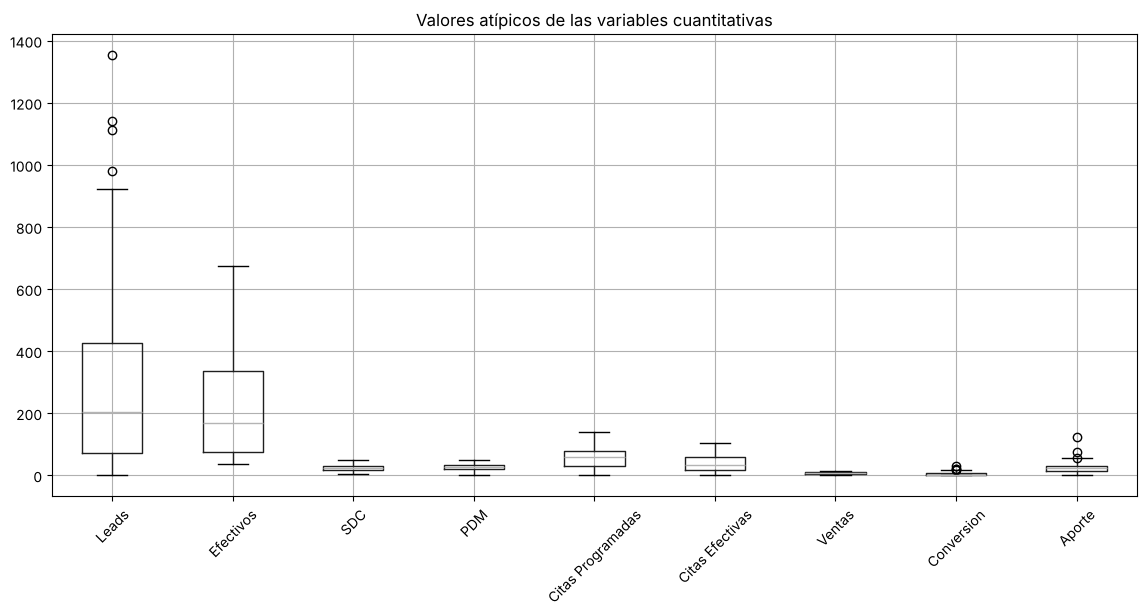

In [21]:
# Separar las variables cuantitativas
cuantitativas = data_sin_nulos.select_dtypes(include=["number"])

# Visualizar valores atípicos de las variables cuantitativas
plt.figure(figsize=(14, 6))
cuantitativas.boxplot()
plt.xticks(rotation=45)
plt.title("Valores atípicos de las variables cuantitativas")
plt.show()

In [22]:
# Identificar valores atípicos por canal
for canal in data_sin_nulos["Canal"].unique():
    datos_canal = data_sin_nulos[data_sin_nulos["Canal"] == canal]
    cuant_canal = datos_canal.select_dtypes(include=["number"])

    Q1 = cuant_canal.quantile(0.25)
    Q3 = cuant_canal.quantile(0.75)
    IQR = Q3 - Q1

    atipicos = (
        (cuant_canal < Q1 - 1.5 * IQR) |
        (cuant_canal > Q3 + 1.5 * IQR)
    ).sum()

    print("\n", canal)
    print(atipicos)


 Piso
0
Leads                2
Efectivos            1
SDC                  1
PDM                  0
Citas Programadas    0
Citas Efectivas      0
Ventas               2
Conversion           1
Aporte               1
dtype: int64

 Plazas
0
Leads                0
Efectivos            0
SDC                  0
PDM                  0
Citas Programadas    0
Citas Efectivas      0
Ventas               0
Conversion           0
Aporte               0
dtype: int64

 Digital
0
Leads                0
Efectivos            0
SDC                  0
PDM                  0
Citas Programadas    0
Citas Efectivas      1
Ventas               0
Conversion           1
Aporte               0
dtype: int64


In [23]:
# Mostrar los valores atípicos identificados por canal
for canal in data_sin_nulos["Canal"].unique():
    datos_canal = data_sin_nulos[data_sin_nulos["Canal"] == canal]
    cuant_canal = datos_canal.select_dtypes(include=["number"])

    Q1 = cuant_canal.quantile(0.25)
    Q3 = cuant_canal.quantile(0.75)
    IQR = Q3 - Q1

    mascara = (
        (cuant_canal < Q1 - 1.5 * IQR) |
        (cuant_canal > Q3 + 1.5 * IQR)).any(axis=1)

    print("\n", canal)
    display(datos_canal.loc[mascara])


 Piso


,Mes,Leads,Efectivos,SDC,PDM,Citas Programadas,Citas Efectivas,Ventas,Conversion,Aporte,Canal
0,"Febrero, 24",329,NaN,NaN,22.0,9.0,4.0,9,2.74,75.00,Piso
1,"Marzo, 24",19,NaN,NaN,13.0,28.0,16.0,4,21.05,57.14,Piso
2,"Abril, 24",76,NaN,NaN,35.0,15.0,6.0,10,13.16,125.00,Piso
3,"Mayo, 24",87,NaN,NaN,40.0,38.0,16.0,1,1.15,7.69,Piso
5,"Julio, 24",92,NaN,51.0,35.0,75.0,57.0,10,10.87,47.62,Piso
14,"Abril, 25",43,43.0,13.0,28.0,34.0,34.0,13,30.23,43.33,Piso
27,"Mayo, 26",115,115.0,24.0,45.0,73.0,59.0,9,7.83,25.71,Piso
29,"Julio,26",36,36.0,7.0,16.0,11.0,8.0,2,5.56,6.06,Piso



 Plazas


,Mes,Leads,Efectivos,SDC,PDM,Citas Programadas,Citas Efectivas,Ventas,Conversion,Aporte,Canal



 Digital


,Mes,Leads,Efectivos,SDC,PDM,Citas Programadas,Citas Efectivas,Ventas,Conversion,Aporte,Canal
71,"Enero, 25",202,NaN,21.0,22.0,74.0,37.0,9,4.46,34.62,Digital
87,"Mayo, 26",667,170.0,30.0,35.0,140.0,103.0,9,1.35,25.71,Digital


Se identificaron posibles valores atípicos mediante el método IQR y se revisaron por canal,
ya que Piso, Plazas y Digital manejan escalas diferentes.
Los valores detectados se conservaron porque corresponden a observaciones reales de cada canal y
no se encontró evidencia suficiente para considerarlos errores o sustituirlos.

# ETAPA 4: ANOVA Y ANOVA FACTORIAL

Variables objetivo analizadas: **Ventas**, **Leads** y **Conversion**.
Factores: **Canal** (Piso, Plazas, Digital) y **Año** (2024, 2025, 2026).

In [24]:
#Transformación: creamos la variable categórica Año a partir de los dos últimos dígitos de Mes ("Febrero, 24" -> "2024")
df = data_sin_nulos.copy()
df["Año"] = "20" + df["Mes"].str[-2:]
df[["Mes", "Año", "Canal", "Ventas", "Leads", "Conversion"]]

,Mes,Año,Canal,Ventas,Leads,Conversion
0,"Febrero, 24",2024,Piso,9,329,2.74
1,"Marzo, 24",2024,Piso,4,19,21.05
2,"Abril, 24",2024,Piso,10,76,13.16
3,"Mayo, 24",2024,Piso,1,87,1.15
4,"Junio, 24",2024,Piso,3,55,5.45
...,...,...,...,...,...,...
85,"Marzo, 26",2026,Digital,11,980,1.12
86,"Abril, 26",2026,Digital,8,834,0.96
87,"Mayo, 26",2026,Digital,9,667,1.35
88,"Junio, 26",2026,Digital,7,748,0.94


In [25]:
#Obtengo las categorías de la variable (Canal)
grupos = pd.unique(df['Canal'].values)
grupos

<StringArray>
['Piso', 'Plazas', 'Digital']
Length: 3, dtype: str

## Variable objetivo 1: Ventas

<Axes: title={'center': 'Ventas'}, xlabel='Canal'>

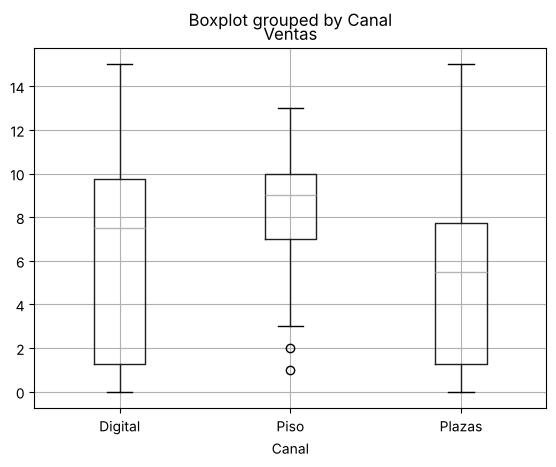

In [26]:
#Analizamos los diagrama de caja de la variable objetivo "Ventas" por cada categoria
# de la variable independiente "Canal" (tipo de dato categórico)
df.boxplot("Ventas", by="Canal")

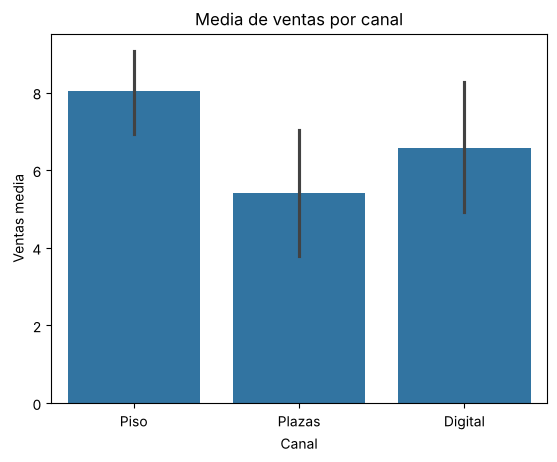

In [27]:
# Gráfico de barras con barras de error (por defecto muestra el IC al 95%)
sns.barplot(data=df, x="Canal", y="Ventas", errorbar=('ci', 95))
plt.title("Media de ventas por canal")
plt.ylabel("Ventas media")
plt.xlabel("Canal")
plt.show()

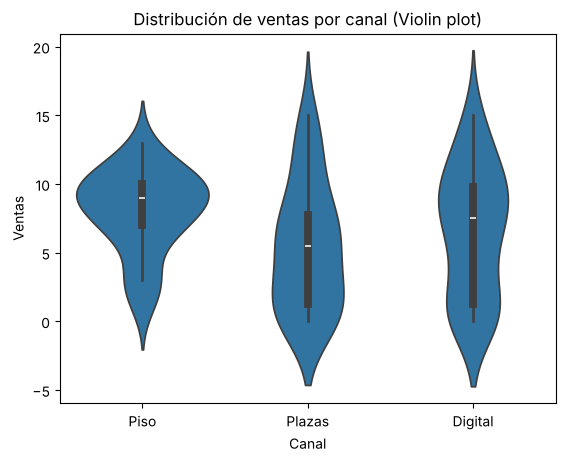

In [28]:
# Gráfico de violín
sns.violinplot(data=df, x="Canal", y="Ventas", inner="box")
plt.title("Distribución de ventas por canal (Violin plot)")
plt.ylabel("Ventas")
plt.xlabel("Canal")
plt.show()

**SCIPY ONEWAY (ANOVA)**

In [29]:
#Defino grupos donde me entrega la columna Ventas separada por grupos de las
#categorías de la columna Canal: "Piso", "Plazas" y "Digital"
Ventas_Piso = df.Ventas[df.Canal == "Piso"]
Ventas_Plazas = df.Ventas[df.Canal == "Plazas"]
Ventas_Digital = df.Ventas[df.Canal == "Digital"]

In [30]:
#p-value < 0.05, se rechaza la hipótesis de que todas las medias son iguales
#p-value < 0.05, implica que la variable categórica influye en la variable
# cuantitativa
anova = stats.f_oneway(Ventas_Piso, Ventas_Plazas, Ventas_Digital)
anova

F_onewayResult(statistic=np.float64(3.022413869551723), pvalue=np.float64(0.053823906470309))

**STATSMODELS (ANOVA)**

In [31]:
#p-value < 0.05, se rechaza la hipótesis de que todas las medias son iguales
mod = ols('Ventas ~ Canal', data=df).fit()
anova_table = sm.stats.anova_lm(mod, typ=1)
print(anova_table)

            df       sum_sq    mean_sq         F    PR(>F)
Canal      2.0   104.466667  52.233333  3.022414  0.053824
Residual  87.0  1503.533333  17.281992       NaN       NaN


**STATSMODELS (ANOVA FACTORIAL)**

In [32]:
#p-value < 0.05, se rechaza la hipótesis de que todas las medias son iguales
# ANOVA Factorial (Múltiples factores con interacción): Canal, Año y Canal:Año
mod = ols('Ventas ~ Canal + Año + Canal:Año', data=df).fit()
anova_table = sm.stats.anova_lm(mod, typ=1)
print(anova_table)

             df      sum_sq     mean_sq          F        PR(>F)
Canal       2.0  104.466667   52.233333   4.954479  9.334105e-03
Año         2.0  562.357864  281.178932  26.670616  1.262309e-09
Canal:Año   4.0   87.220924   21.805231   2.068288  9.256292e-02
Residual   81.0  853.954545   10.542649        NaN           NaN


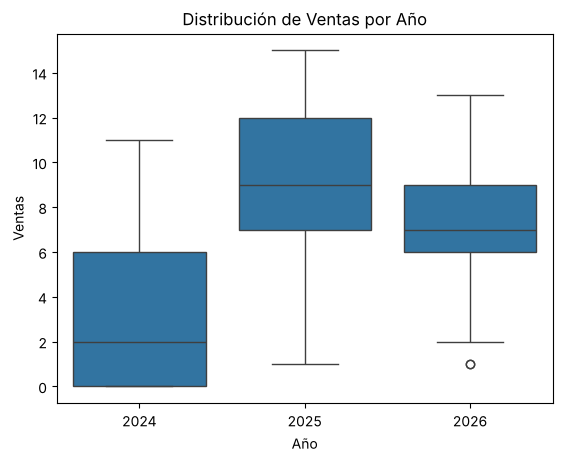

In [33]:
#Grafica variable Ventas vs Año
sns.boxplot(data=df, x='Año', y='Ventas')
plt.title("Distribución de Ventas por Año")
plt.show()

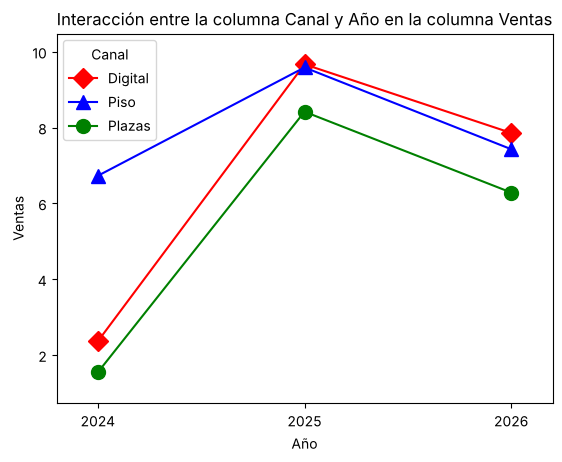

In [34]:
fig = interaction_plot(df['Año'], df['Canal'], df['Ventas'],
                       colors=['red', 'blue', 'green'], markers=['D', '^', 'o'], ms=10)
plt.title("Interacción entre la columna Canal y Año en la columna Ventas")
plt.xlabel("Año")
plt.ylabel("Ventas")
plt.show()

## Variable objetivo 2: Leads

<Axes: title={'center': 'Leads'}, xlabel='Canal'>

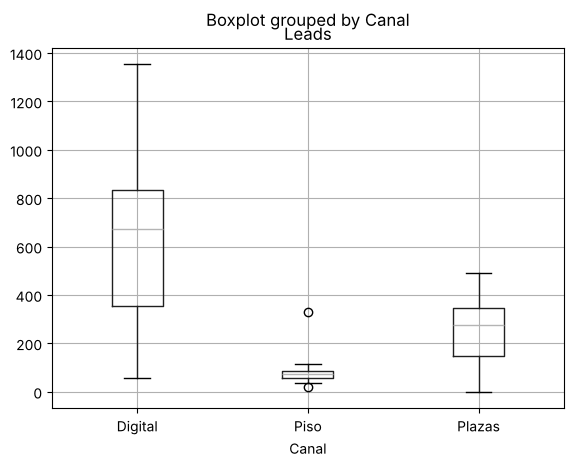

In [35]:
#Analizamos los diagrama de caja de la variable objetivo "Leads" por cada categoria
# de la variable independiente "Canal" (tipo de dato categórico)
df.boxplot("Leads", by="Canal")

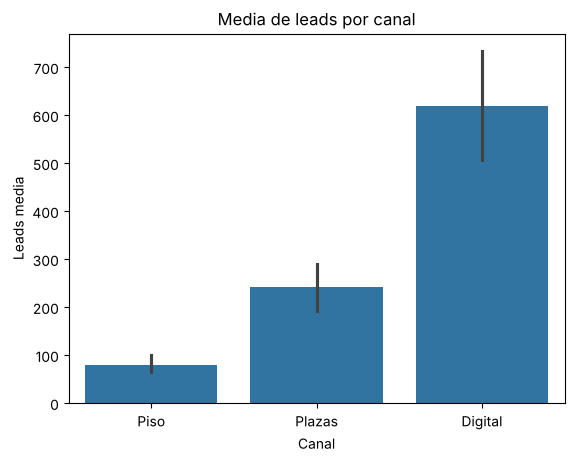

In [36]:
# Gráfico de barras con barras de error (por defecto muestra el IC al 95%)
sns.barplot(data=df, x="Canal", y="Leads", errorbar=('ci', 95))
plt.title("Media de leads por canal")
plt.ylabel("Leads media")
plt.xlabel("Canal")
plt.show()

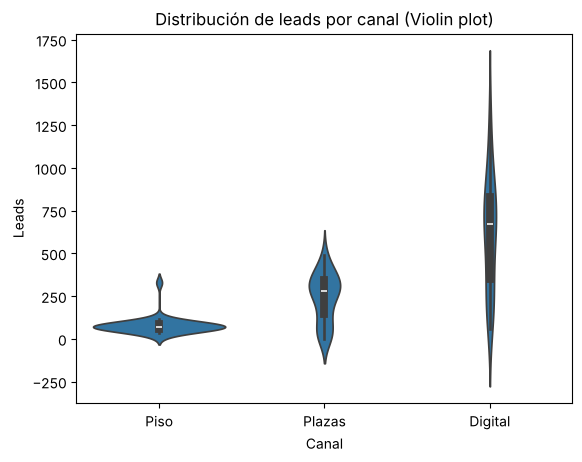

In [37]:
# Gráfico de violín
sns.violinplot(data=df, x="Canal", y="Leads", inner="box")
plt.title("Distribución de leads por canal (Violin plot)")
plt.ylabel("Leads")
plt.xlabel("Canal")
plt.show()

**SCIPY ONEWAY (ANOVA)**

In [38]:
#Defino grupos donde me entrega la columna Leads separada por grupos de las
#categorías de la columna Canal: "Piso", "Plazas" y "Digital"
Leads_Piso = df.Leads[df.Canal == "Piso"]
Leads_Plazas = df.Leads[df.Canal == "Plazas"]
Leads_Digital = df.Leads[df.Canal == "Digital"]

In [39]:
#p-value < 0.05, se rechaza la hipótesis de que todas las medias son iguales
#p-value < 0.05, implica que la variable categórica influye en la variable
# cuantitativa
anova = stats.f_oneway(Leads_Piso, Leads_Plazas, Leads_Digital)
anova

F_onewayResult(statistic=np.float64(52.39101249474307), pvalue=np.float64(1.1666587461298184e-15))

**STATSMODELS (ANOVA)**

In [40]:
#p-value < 0.05, se rechaza la hipótesis de que todas las medias son iguales
mod = ols('Leads ~ Canal', data=df).fit()
anova_table = sm.stats.anova_lm(mod, typ=1)
print(anova_table)

            df        sum_sq       mean_sq          F        PR(>F)
Canal      2.0  4.602536e+06  2.301268e+06  52.391012  1.166659e-15
Residual  87.0  3.821463e+06  4.392486e+04        NaN           NaN


**STATSMODELS (ANOVA FACTORIAL)**

In [41]:
#p-value < 0.05, se rechaza la hipótesis de que todas las medias son iguales
# ANOVA Factorial (Múltiples factores con interacción): Canal, Año y Canal:Año
mod = ols('Leads ~ Canal + Año + Canal:Año', data=df).fit()
anova_table = sm.stats.anova_lm(mod, typ=1)
print(anova_table)

             df        sum_sq       mean_sq          F        PR(>F)
Canal       2.0  4.602536e+06  2.301268e+06  54.787503  8.932491e-16
Año         2.0  1.877229e+05  9.386146e+04   2.234609  1.135923e-01
Canal:Año   4.0  2.314550e+05  5.786374e+04   1.377593  2.490164e-01
Residual   81.0  3.402285e+06  4.200352e+04        NaN           NaN


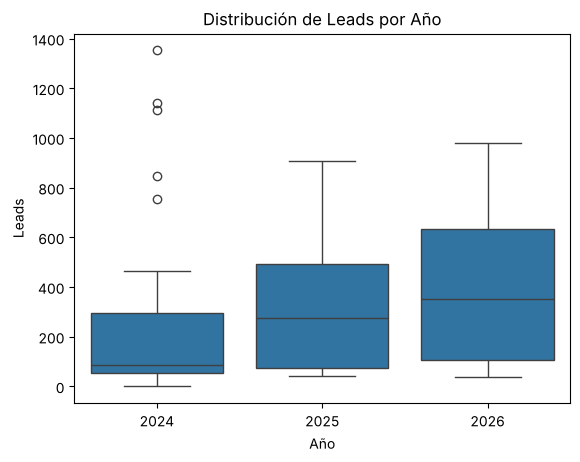

In [42]:
#Grafica variable Leads vs Año
sns.boxplot(data=df, x='Año', y='Leads')
plt.title("Distribución de Leads por Año")
plt.show()

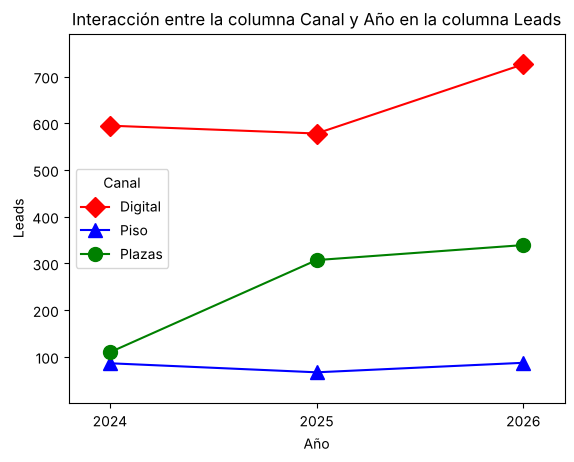

In [43]:
fig = interaction_plot(df['Año'], df['Canal'], df['Leads'],
                       colors=['red', 'blue', 'green'], markers=['D', '^', 'o'], ms=10)
plt.title("Interacción entre la columna Canal y Año en la columna Leads")
plt.xlabel("Año")
plt.ylabel("Leads")
plt.show()

## Variable objetivo 3: Conversion

<Axes: title={'center': 'Conversion'}, xlabel='Canal'>

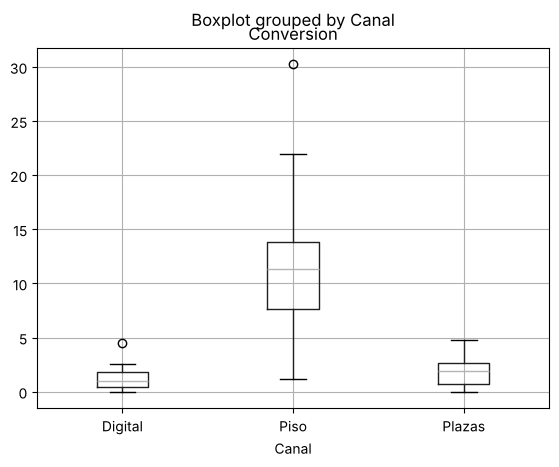

In [44]:
#Analizamos los diagrama de caja de la variable objetivo "Conversion" por cada categoria
# de la variable independiente "Canal" (tipo de dato categórico)
df.boxplot("Conversion", by="Canal")

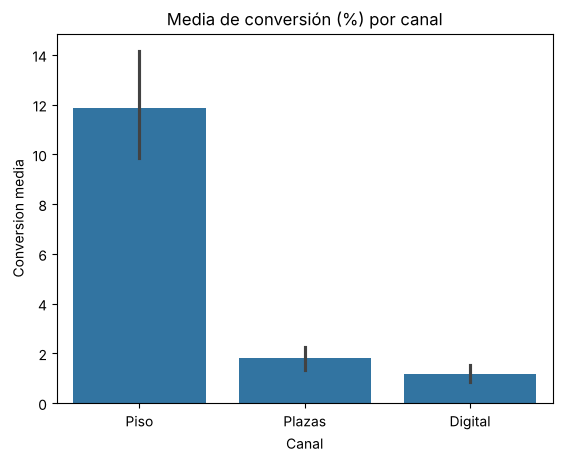

In [45]:
# Gráfico de barras con barras de error (por defecto muestra el IC al 95%)
sns.barplot(data=df, x="Canal", y="Conversion", errorbar=('ci', 95))
plt.title("Media de conversión (%) por canal")
plt.ylabel("Conversion media")
plt.xlabel("Canal")
plt.show()

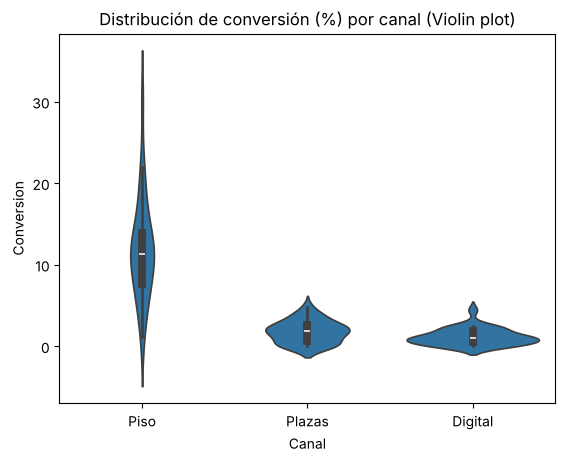

In [46]:
# Gráfico de violín
sns.violinplot(data=df, x="Canal", y="Conversion", inner="box")
plt.title("Distribución de conversión (%) por canal (Violin plot)")
plt.ylabel("Conversion")
plt.xlabel("Canal")
plt.show()

**SCIPY ONEWAY (ANOVA)**

In [47]:
#Defino grupos donde me entrega la columna Conversion separada por grupos de las
#categorías de la columna Canal: "Piso", "Plazas" y "Digital"
Conversion_Piso = df.Conversion[df.Canal == "Piso"]
Conversion_Plazas = df.Conversion[df.Canal == "Plazas"]
Conversion_Digital = df.Conversion[df.Canal == "Digital"]

In [48]:
#p-value < 0.05, se rechaza la hipótesis de que todas las medias son iguales
#p-value < 0.05, implica que la variable categórica influye en la variable
# cuantitativa
anova = stats.f_oneway(Conversion_Piso, Conversion_Plazas, Conversion_Digital)
anova

F_onewayResult(statistic=np.float64(84.11035029549596), pvalue=np.float64(4.6584988388239245e-21))

**STATSMODELS (ANOVA)**

In [49]:
#p-value < 0.05, se rechaza la hipótesis de que todas las medias son iguales
mod = ols('Conversion ~ Canal', data=df).fit()
anova_table = sm.stats.anova_lm(mod, typ=1)
print(anova_table)

            df       sum_sq      mean_sq         F        PR(>F)
Canal      2.0  2167.619407  1083.809703  84.11035  4.658499e-21
Residual  87.0  1121.044483    12.885569       NaN           NaN


**STATSMODELS (ANOVA FACTORIAL)**

In [50]:
#p-value < 0.05, se rechaza la hipótesis de que todas las medias son iguales
# ANOVA Factorial (Múltiples factores con interacción): Canal, Año y Canal:Año
mod = ols('Conversion ~ Canal + Año + Canal:Año', data=df).fit()
anova_table = sm.stats.anova_lm(mod, typ=1)
print(anova_table)

             df       sum_sq      mean_sq          F        PR(>F)
Canal       2.0  2167.619407  1083.809703  99.979468  1.329254e-22
Año         2.0   148.140605    74.070302   6.832850  1.810676e-03
Canal:Año   4.0    94.837732    23.709433   2.187152  7.770368e-02
Residual   81.0   878.066146    10.840323        NaN           NaN


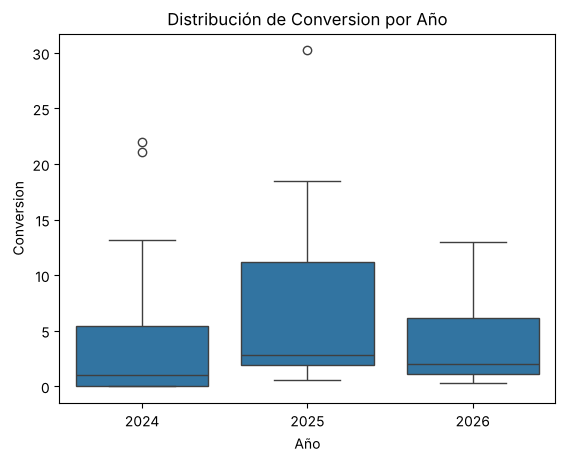

In [51]:
#Grafica variable Conversion vs Año
sns.boxplot(data=df, x='Año', y='Conversion')
plt.title("Distribución de Conversion por Año")
plt.show()

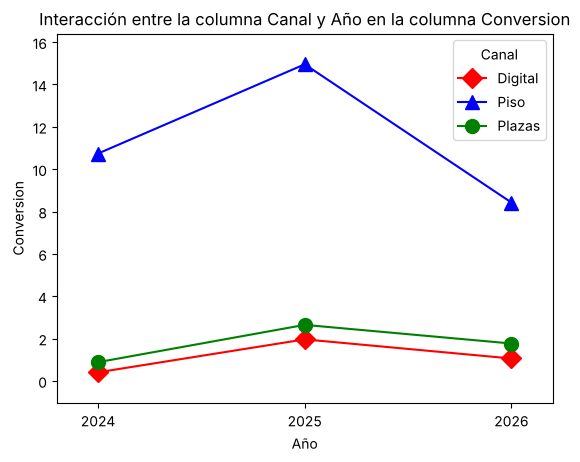

In [52]:
fig = interaction_plot(df['Año'], df['Canal'], df['Conversion'],
                       colors=['red', 'blue', 'green'], markers=['D', '^', 'o'], ms=10)
plt.title("Interacción entre la columna Canal y Año en la columna Conversion")
plt.xlabel("Año")
plt.ylabel("Conversion")
plt.show()

# EXTRA (BONUS): WIDGETS ADICIONALES A LA PLANTILLA

Como elemento extra a la plantilla vista en clase, se agregan una **tabla resumen**, un **heatmap** y una **gráfica de líneas en el tiempo**,
que complementan la lectura del ANOVA Factorial al mostrar al mismo tiempo los dos factores (Canal y Año).

In [53]:
# EXTRA - TABLA: media, desviación estándar y número de meses de Ventas por Canal y Año
tabla_resumen = df.groupby(["Canal", "Año"])["Ventas"].agg(["mean", "std", "count"]).round(2)
tabla_resumen

mean   std  count
Canal   Año                    
Digital 2024  2.36  3.26     11
        2025  9.67  3.26     12
        2026  7.86  3.85      7
Piso    2024  6.73  3.47     11
        2025  9.58  1.98     12
        2026  7.43  2.88      7
Plazas  2024  1.55  2.21     11
        2025  8.42  4.64     12
        2026  6.29  2.69      7

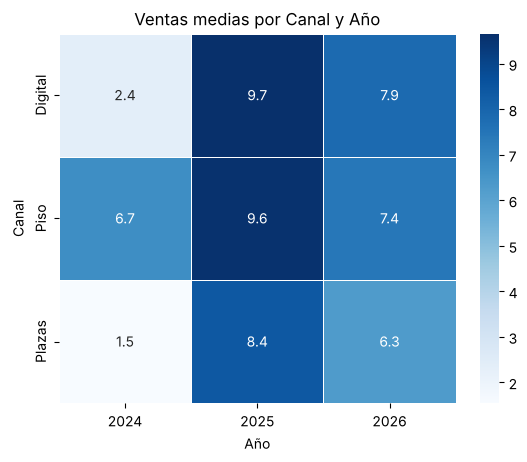

In [54]:
# EXTRA - HEATMAP: ventas medias por Canal y Año (más oscuro = más ventas)
ventas_medias = df.pivot_table(index="Canal", columns="Año", values="Ventas", aggfunc="mean")

sns.heatmap(ventas_medias, annot=True, fmt=".1f", cmap="Blues", linewidths=0.5)
plt.title("Ventas medias por Canal y Año")
plt.xlabel("Año")
plt.ylabel("Canal")
plt.show()

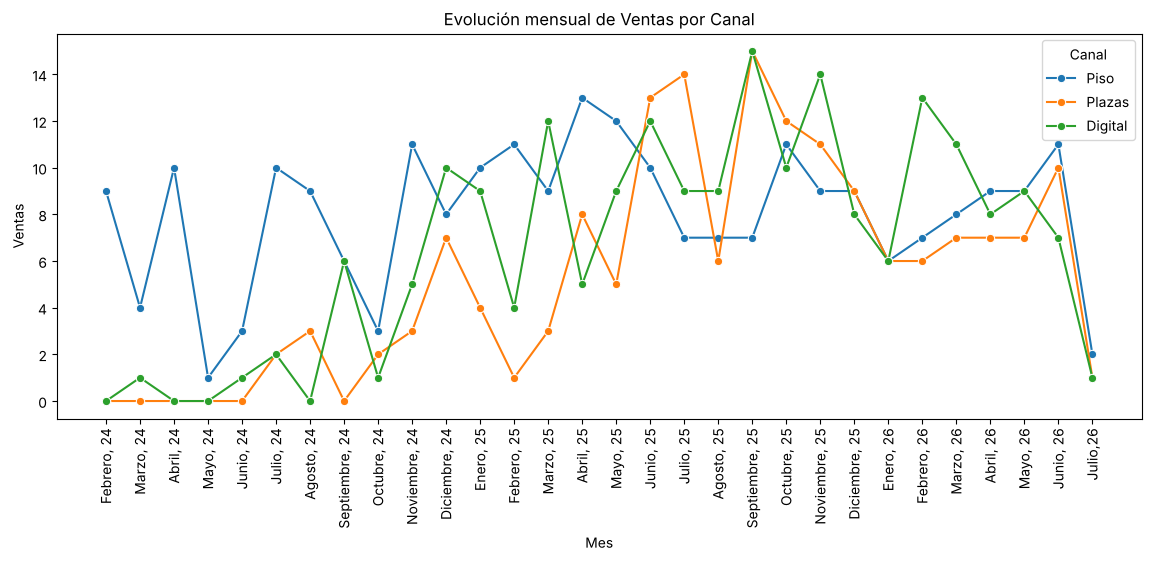

In [55]:
# EXTRA - GRÁFICA DE LÍNEAS: evolución mensual de Ventas por Canal (Feb 2024 - Jul 2026)
plt.figure(figsize=(14, 5))
sns.lineplot(data=df, x="Mes", y="Ventas", hue="Canal", marker="o", sort=False)
plt.title("Evolución mensual de Ventas por Canal")
plt.xlabel("Mes")
plt.ylabel("Ventas")
plt.xticks(rotation=90)
plt.show()

**Conclusión**

**Ventas:** Piso es el canal que más vende (8.0 ventas al mes en promedio, contra 6.6 de Digital y 5.4 de Plazas). Sin embargo, en el ANOVA de una vía el p-value (0.054) es mayor a 0.05: la diferencia existe, pero no alcanza a ser estadísticamente significativa por sí sola, debido a la alta variación mensual de las ventas. En el ANOVA Factorial, Canal (p = 0.009) y Año (p < 0.001) sí son significativos: el Año explica la mayor parte de la variación (las ventas medias pasan de 3.5 en 2024 a 9.2 en 2025) y, al controlarlo, aparece la diferencia entre canales. La ventaja de Piso se concentra en 2024; a partir de 2025 Digital lo alcanza. La interacción Canal:Año (p = 0.093) no es significativa.

**Leads:** el Canal es altamente significativo (p < 0.001). Digital genera en promedio 619 leads al mes, Plazas 242 y Piso 79. El Año (p = 0.11) y la interacción (p = 0.25) no son significativos: el volumen de leads depende del canal, no del periodo.

**Conversion:** el Canal es altamente significativo (p < 0.001) y el Año también (p = 0.002). Piso convierte en promedio 11.9% contra 1.8% de Plazas y 1.2% de Digital. La interacción (p = 0.078) no es significativa.

**Conclusión general:** Digital es el canal que más leads genera y Piso el que mejor los convierte. Piso sigue siendo el canal que más vende en el acumulado, pero Digital lo alcanzó desde 2025 gracias a su volumen de leads. La principal fuente de variación de las ventas es el Año.